# 🚕 Q-Learning en Taxi-v4 — Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [1]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation


# Semillas para reproducibilidad
random.seed(0)
np.random.seed(0)


## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [2]:
env = gym.make("Taxi-v4", render_mode="rgb_array")

print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)
env.action_space.seed(0)  # reproducibilidad de las acciones aleatorias


Número de estados: 500
Número de acciones: 6


0

### Pregunta 1

¿Cuántos estados y cuántas acciones tiene Taxi-v4?

Explique brevemente por qué Taxi tiene muchos más estados que FrozenLake.


**Respuesta 1.** Taxi-v4 tiene **500 estados** y **6 acciones**.

Los 500 estados salen de combinar: 25 posiciones del taxi (cuadrícula 5×5) × 5 ubicaciones del pasajero (4 paradas R, G, Y, B + "dentro del taxi") × 4 destinos posibles = 25·5·4 = 500. FrozenLake 4×4 solo tiene 16 estados porque su estado es únicamente la posición del agente. En Taxi el estado tiene que codificar además *dónde está el pasajero* y *a dónde quiere ir*, y el número de estados crece de forma multiplicativa con cada variable.

## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [3]:
state, info = env.reset(seed=42)

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)


Estado: 386
Acción: 5
Nuevo estado: 386
Recompensa: -10
Terminated: False


### Pregunta 2

En la interacción anterior identifique:

$$
s_t,\quad a_t,\quad r_{t+1},\quad s_{t+1}
$$

¿Qué representa cada elemento?


**Respuesta 2.** Con `seed=42` y la acción aleatoria sorteada, la salida fue:

- $s_t$ = **386** (`state`): estado inicial; entero 0–499 que codifica posición del taxi, ubicación del pasajero y destino.
- $a_t$ = **5** (`action`, *Dropoff*): acción elegida al azar entre las 6 posibles.
- $r_{t+1}$ = **−10** (`reward`): recompensa por ejecutar *dropoff* de forma ilegal (el pasajero no estaba en el taxi). En Taxi, −1 es el costo de cada paso normal, −10 el de un pickup/dropoff ilegal y +20 el de dejar correctamente al pasajero.
- $s_{t+1}$ = **386** (`next_state`): el estado no cambió, porque una acción ilegal no mueve nada. `terminated=False`: el episodio continúa.

## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [4]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]


Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3

¿Cuántos valores debe aprender el agente en total?

Calcule:

$$
|\mathcal{S}| \times |\mathcal{A}|
$$


In [5]:
print("Valores de Q a aprender:", n_states, "x", n_actions, "=", n_states * n_actions)

Valores de Q a aprender: 500 x 6 = 3000


**Respuesta 3.** $|\mathcal{S}|\times|\mathcal{A}| = 500 \times 6 = 3000$ valores $Q(s,a)$. Es una tabla pequeña, pero en la práctica no todos los pares son alcanzables o relevantes (por ejemplo, algunas combinaciones pasajero/destino iguales no ocurren al inicio), así que el agente efectivamente aprende un poco menos de 3000 valores útiles.

## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [6]:
def choose_action(Q, state, epsilon, env):
    # 1. decidir si explorar o explotar
    if random.random() < epsilon:
        # Exploración: acción aleatoria válida
        return env.action_space.sample()
    # Explotación: argmax_a Q(s,a) (desempate aleatorio entre acciones con igual valor,
    # importante al inicio cuando toda la fila vale 0)
    q_values = Q[state]
    best_actions = np.flatnonzero(q_values == np.max(q_values))
    return int(np.random.choice(best_actions))


## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [7]:
def update_q(Q, state, action, reward, next_state, alpha, gamma):
    # Target: r + gamma * max_a' Q(s', a')
    target = reward + gamma * np.max(Q[next_state])
    # Error TD: target - Q(s,a)
    td_error = target - Q[state, action]
    # Actualización
    Q[state, action] += alpha * td_error
    return Q


## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [8]:
def train_q_learning(
    env,
    Q,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
):
    rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps):

            # 1: escoger acción (epsilon-greedy)
            action = choose_action(Q, state, epsilon, env)

            # 2: ejecutar acción en el ambiente
            next_state, reward, terminated, truncated, _ = env.step(action)

            # 3: actualizar Q
            # (solo se bootstrappea si el episodio NO terminó de verdad; en estado terminal V(s')=0)
            if terminated:
                Q[state, action] += alpha * (reward - Q[state, action])
            else:
                update_q(Q, state, action, reward, next_state, alpha, gamma)

            # 4: actualizar estado y recompensa acumulada
            state = next_state
            total_reward += reward

            # 5: terminar si corresponde
            if terminated or truncated:
                break

        rewards.append(total_reward)

    return Q, rewards


## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [9]:
Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)


In [10]:
print("Entrenamiento terminado.")
print("Recompensa media primeros 100 episodios :", np.mean(rewards[:100]))
print("Recompensa media últimos 100 episodios  :", np.mean(rewards[-100:]))
print("Pares (s,a) visitados (Q != 0):", int(np.count_nonzero(Q_trained)), "de", Q_trained.size)

Entrenamiento terminado.
Recompensa media primeros 100 episodios : -307.26
Recompensa media últimos 100 episodios  : 3.08
Pares (s,a) visitados (Q != 0): 2398 de 3000


## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


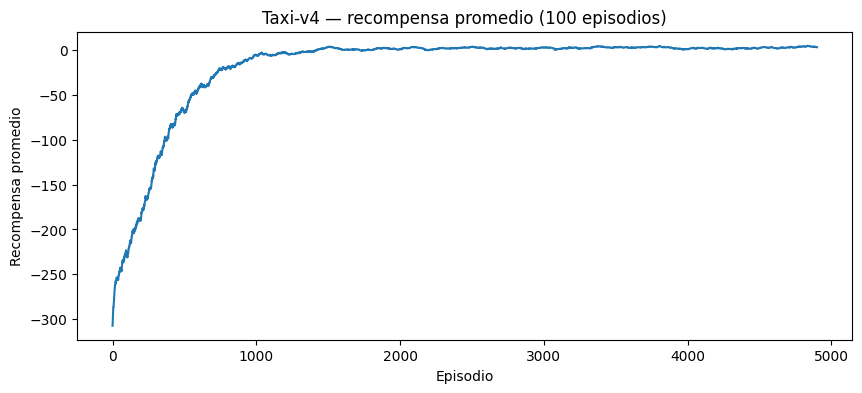

In [11]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi-v4 — recompensa promedio ({window} episodios)")
plt.show()


In [12]:
# Desempeño de la política greedy (sin exploración) sobre 200 episodios de evaluación
def evaluate(env, Q, episodes=200, max_steps=200):
    rets, steps, ok = [], [], 0
    for _ in range(episodes):
        s, _ = env.reset()
        tot, n = 0, 0
        for _ in range(max_steps):
            a = int(np.random.choice(np.flatnonzero(Q[s] == Q[s].max())))
            s, r, term, trunc, _ = env.step(a)
            tot += r; n += 1
            if term or trunc: break
        rets.append(tot); steps.append(n); ok += int(term)
    return np.mean(rets), np.mean(steps), ok / episodes

for name, QQ in [("Sin entrenar", Q_initial), ("Entrenado", Q_trained)]:
    m, st, sr = evaluate(env, QQ)
    print(f"{name:13s} | recompensa media: {m:8.2f} | pasos medios: {st:6.1f} | éxito: {sr*100:5.1f}%")

# Primer episodio en que la media móvil supera 0
first_pos = next((i + window for i, v in enumerate(moving_average) if v > 0), None)
print("Primer episodio con media móvil > 0:", first_pos)
for ep in [100, 250, 500, 1000, 2000, 3000, 5000]:
    print(f"Media móvil hasta episodio {ep:5d}:", round(float(np.mean(rewards[max(0, ep-100):ep])), 2))

Sin entrenar  | recompensa media:  -784.02 | pasos medios:  196.9 | éxito:   4.0%
Entrenado     | recompensa media:     8.05 | pasos medios:   12.9 | éxito: 100.0%
Primer episodio con media móvil > 0: 1525
Media móvil hasta episodio   100: -307.26
Media móvil hasta episodio   250: -203.99
Media móvil hasta episodio   500: -86.13
Media móvil hasta episodio  1000: -14.47
Media móvil hasta episodio  2000: 2.07
Media móvil hasta episodio  3000: 1.72
Media móvil hasta episodio  5000: 3.08


### Pregunta 4

Describa la curva de aprendizaje.

- ¿La recompensa promedio mejora?
- ¿Después de aproximadamente cuántos episodios comienza a estabilizarse?
- ¿El comportamiento observado indica convergencia perfecta o solamente una política razonablemente buena?


**Respuesta 4.**

- **¿Mejora la recompensa promedio?** Sí, de forma muy marcada. La media móvil (100 episodios) parte en ≈ **−307** (primeros 100 episodios, el agente casi nunca completa la tarea y acumula penalizaciones de −10), sube a ≈ −204 hacia el episodio 250, ≈ −86 hacia el 500 y ≈ −14 hacia el 1000. Cruza a valores positivos alrededor del episodio **~1500** y termina en ≈ **+3**.
- **¿Cuándo se estabiliza?** Aproximadamente después de **~2000 episodios**: del 2000 al 5000 la media se mueve solo entre ≈ +1.7 y +3.1.
- **¿Convergencia perfecta o política razonablemente buena?** Lo segundo, con matices. La política *greedy* evaluada en 200 episodios nuevos obtiene **100 % de éxito, ≈13 pasos y recompensa media ≈ +7.9**, lo que es casi el máximo posible en Taxi (≈ 8), así que la política aprendida es muy buena. Pero la curva de entrenamiento queda en ≈ +3 y sigue ruidosa porque ε = 0.1 mantiene un 10 % de acciones aleatorias que a veces arruinan un episodio (por eso la media de entrenamiento es menor que la de evaluación). Además, solo 2398 de los 3000 valores Q fueron actualizados (los demás nunca se visitaron o corresponden a pares que no ocurren), y con α constante los valores siguen oscilando un poco. No se puede afirmar convergencia exacta de $Q$ a $Q^*$, solo una política casi óptima.

## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [13]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward


def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [14]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)


error: XDG_RUNTIME_DIR is invalid or not set in the environment.


Recompensa total sin entrenamiento: -167


Ahora observe el agente entrenado.


In [15]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)


Recompensa total después del entrenamiento: 10


### Pregunta 5

Compare los dos episodios.

- ¿Qué diferencias observa en el comportamiento del taxi?
- ¿El taxi sin entrenamiento logra completar la tarea?
- ¿El agente entrenado evita acciones innecesarias?
- ¿Qué evidencia visual le permite afirmar que el agente aprendió?


**Respuesta 5.** (Con `seed=7`.)

| | Sin entrenar (Q = 0) | Entrenado |
|---|---|---|
| Recompensa total | **−167** en 50 pasos | **+10** |
| Pasos | agota los 50 pasos | **11 pasos** |
| ¿Completa la tarea? | No | Sí (episodio termina con `terminated=True`) |

- **Diferencias:** con la Q-table en cero, todas las acciones empatan y la elección es prácticamente aleatoria: el taxi da vueltas, choca con paredes y repite pickups/dropoffs ilegales (−10 cada uno). El agente entrenado va directo hacia el pasajero, lo recoge, se dirige al destino y lo deja.
- **¿El sin entrenar completa la tarea?** No en este episodio; y en la evaluación de 200 episodios solo lo logró el **4 %** de las veces (recompensa media ≈ −784).
- **¿El entrenado evita acciones innecesarias?** Sí. Hace 11 pasos (10 × (−1) + 20 = +10), sin ningún pickup/dropoff ilegal; en promedio necesita ≈ 13 pasos y tiene 100 % de éxito.
- **Evidencia de aprendizaje:** pasar de recompensas muy negativas a positivas, de 50 pasos sin éxito a una ruta corta y directa, sin penalizaciones por acciones ilegales y con el pasajero entregado en el destino correcto.

## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [16]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))


Estado: 123
Q-values: [-2.96083491 -3.97315323 -0.38890062  3.94947757 -6.08708853 -5.49220933]
Mejor acción: 3


### Pregunta 6

Para el estado seleccionado:

1. ¿Cuál es la acción con mayor valor Q?
2. ¿Qué significa que una acción tenga un valor Q mayor que otra?
3. ¿Por qué no podemos interpretar $Q(s,a)$ únicamente como la recompensa inmediata de ejecutar la acción?


**Respuesta 6.** Estado 123 → decodificado: taxi en fila 1, columna 1; pasajero en la parada R (esquina superior izquierda); destino B. Valores aprendidos (orden S, N, E, O, Pickup, Dropoff):

`[-2.96, -3.97, -0.39, 3.95, -6.09, -5.49]`

1. **Acción con mayor Q:** la acción **3 (West/Oeste)**, con Q ≈ **3.95**. Tiene sentido: el pasajero está en R, a la izquierda y arriba del taxi, así que moverse al oeste lo acerca a la recogida.
2. **Significado:** $Q(s,a)$ estima el **retorno descontado esperado** si en $s$ se ejecuta $a$ y luego se sigue la política aprendida. Que una acción tenga mayor Q que otra significa que, según el agente, conduce a una mayor recompensa acumulada a futuro y por eso la política greedy la prefiere. Aquí, Pickup (−6.09) y Dropoff (−5.49) son claramente malas porque son ilegales en ese estado (−10 inmediato); East (−0.39) es mejor que North/South pero peor que West, pues hay una pared a la derecha del taxi.
3. **¿Por qué no es solo la recompensa inmediata?** Porque Q incluye también las recompensas futuras: $Q(s,a) \approx r + \gamma \max_{a'} Q(s',a')$. West da −1 inmediato, igual que casi cualquier movimiento, y aun así su Q es **positivo** (+3.95) porque ese paso encamina hacia recoger y entregar al pasajero (+20 al final). Si Q fuera solo la recompensa inmediata, todas las acciones de movimiento valdrían −1 y el agente no podría distinguir cuál conviene.

## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar:

- $\alpha$
- $\gamma$
- $\epsilon$

### Pregunta 7

Compare el nuevo entrenamiento con el original.

Explique cómo el cambio del hiperparámetro afectó:

- velocidad de aprendizaje,
- estabilidad,
- recompensa final,
- comportamiento observado.


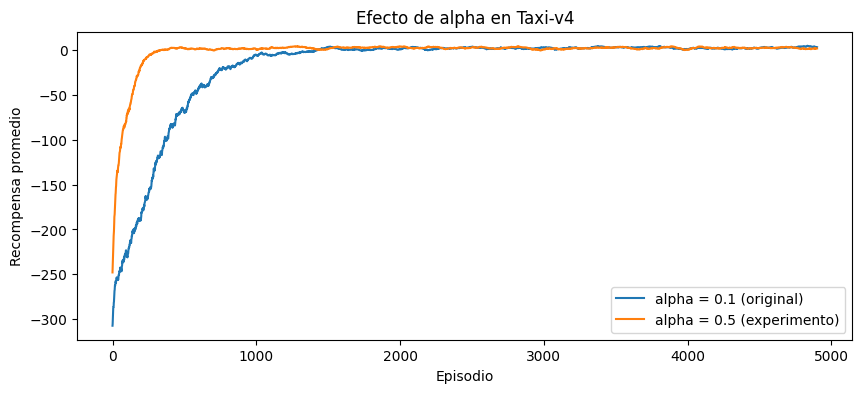

alpha=0.1 | 1er episodio media>0: 1525 | media últimos 100 (entren.):   3.08 | desv. últimos 1000:  8.08 | eval greedy:   7.91 recomp,  13.1 pasos, 100% éxito
alpha=0.5 | 1er episodio media>0: 437 | media últimos 100 (entren.):   1.63 | desv. últimos 1000:  8.25 | eval greedy:   8.24 recomp,  12.8 pasos, 100% éxito


In [17]:
# Experimento: se cambia SOLO alpha (0.1 -> 0.5). gamma=0.95, epsilon=0.1 y episodios=5000 se mantienen.
random.seed(0); np.random.seed(0)
Q_exp, rewards_exp = train_q_learning(
    env, np.zeros((n_states, n_actions)),
    episodes=5000, alpha=0.5, gamma=0.95, epsilon=0.1
)

ma_exp = np.convolve(rewards_exp, np.ones(window) / window, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(moving_average, label="alpha = 0.1 (original)")
plt.plot(ma_exp, label="alpha = 0.5 (experimento)")
plt.xlabel("Episodio"); plt.ylabel("Recompensa promedio")
plt.title("Efecto de alpha en Taxi-v4"); plt.legend(); plt.show()

for name, rw, QQ in [("alpha=0.1", rewards, Q_trained), ("alpha=0.5", rewards_exp, Q_exp)]:
    first = next((i + window for i, v in enumerate(np.convolve(rw, np.ones(window)/window, mode="valid")) if v > 0), None)
    m, st, sr = evaluate(env, QQ)
    print(f"{name} | 1er episodio media>0: {first} | media últimos 100 (entren.): {np.mean(rw[-100:]):6.2f} "
          f"| desv. últimos 1000: {np.std(rw[-1000:]):5.2f} | eval greedy: {m:6.2f} recomp, {st:5.1f} pasos, {sr*100:.0f}% éxito")

**Respuesta 7.** Se modificó **solo α: 0.1 → 0.5** (γ = 0.95, ε = 0.1, 5000 episodios; misma semilla).

| | α = 0.1 | α = 0.5 |
|---|---|---|
| Primer episodio con media móvil > 0 | 1525 | **437** |
| Recompensa media últimos 100 (entrenamiento) | 3.08 | 1.63 |
| Desv. estándar últimos 1000 episodios | 8.08 | 8.25 |
| Evaluación greedy (200 ep.) | 7.91, 13.1 pasos, 100 % éxito | 8.24, 12.8 pasos, 100 % éxito |

- **Velocidad de aprendizaje:** con α = 0.5 el agente aprende mucho más rápido (se vuelve positivo ~3.5 veces antes), porque cada experiencia mueve Q con más fuerza hacia el target.
- **Estabilidad:** en esta corrida no hay diferencia clara (desviaciones de ≈ 8 en ambos casos); en un ambiente determinista como Taxi, un α alto no genera inestabilidad grave. El ruido visible viene sobre todo de ε = 0.1. En ambientes estocásticos un α alto sí tendería a oscilar más. Con una sola semilla las diferencias pequeñas (p. ej. 3.08 vs 1.63 al final) no son concluyentes.
- **Recompensa final:** prácticamente equivalente; ambas políticas greedy obtienen ≈ +8 con 100 % de éxito.
- **Comportamiento observado:** ambas aprenden la misma ruta eficiente de ≈ 13 pasos. La ventaja de α = 0.5 es llegar antes a esa política, no una política mejor.

## Resumen de resultados

- Se implementaron `choose_action` (ε-greedy con desempate aleatorio), `update_q` y `train_q_learning`. En un estado terminal se actualiza sin bootstrapping (target = r), práctica estándar.
- Tras 5000 episodios el agente pasa de ≈ −784 de recompensa media (4 % de éxito) a ≈ **+8** (100 % de éxito, ≈13 pasos).
- Aumentar α de 0.1 a 0.5 acelera el aprendizaje sin cambiar la calidad final.


## Entrega

El notebook debe contener:

1. implementación de `choose_action`;
2. implementación de `update_q`;
3. implementación de `train_q_learning`;
4. curva de aprendizaje;
5. visualización del agente antes y después del entrenamiento;
6. respuestas a las siete preguntas.

No es necesario modificar las funciones auxiliares de visualización.
